
Random dropout
Inactive sensors: [2, 12, 17, 20, 22, 25, 28, 30]
MAE: 0.00090014
RMSE: 0.00331261
Maximum absolute error: 0.04073211

Periodic dropout
Inactive sensors: [1, 5, 9, 13, 17, 21, 25, 29]
MAE: 0.00115346
RMSE: 0.00413643
Maximum absolute error: 0.04299596

Block dropout
Inactive sensors: [12, 13, 14, 15, 16, 17, 18, 19]
MAE: 0.00776819
RMSE: 0.02493858
Maximum absolute error: 0.14171709


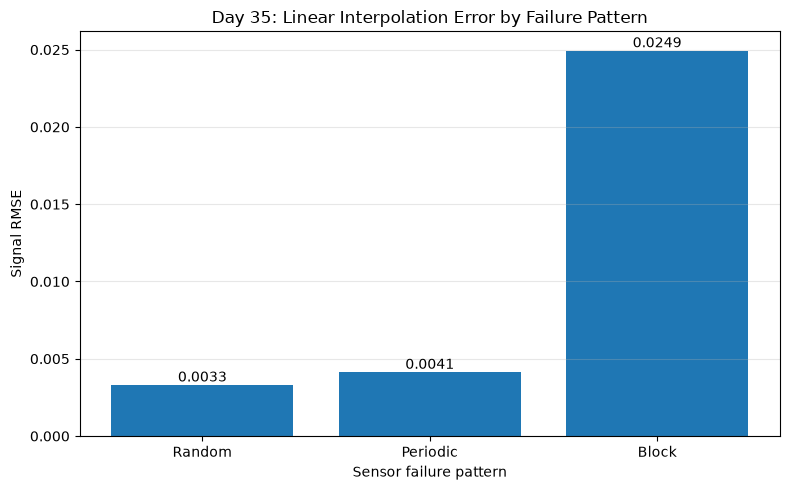

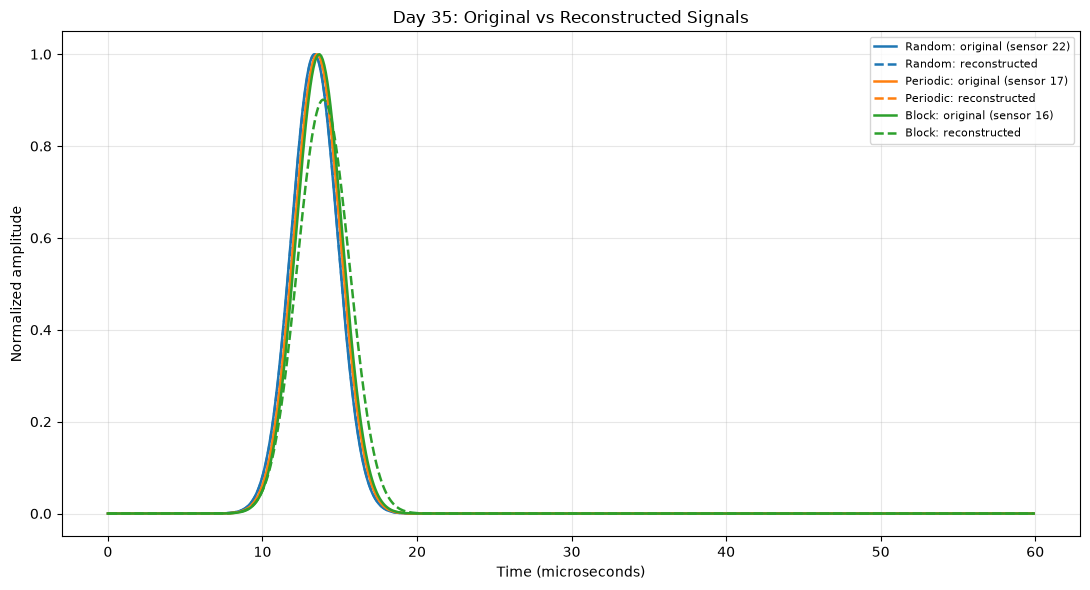


Day 35 completed.
RMSE plot saved to: ..\outputs\day35_linear_interpolation_rmse.png
Signal comparison saved to: ..\outputs\day35_signal_reconstruction_comparison.png
Results saved to: ..\outputs\day35_linear_interpolation_results.json


In [2]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# ==============================================
# Day 35: Linear Interpolation and Failure Patterns
# ==============================================

# 1. Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Simulation parameters
num_sensors = 32
num_samples = 600

fs = 10e6
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

time = np.arange(num_samples) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

# 3. Generate original synthetic signals
signals_full = np.zeros((num_sensors, num_samples))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt(
        (sx - source_x)**2 + source_y**2
    )
    arrival_time = distance / c

    signals_full[i, :] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 4. Define three failure patterns
num_inactive = 8

rng = np.random.default_rng(42)

random_indices = np.sort(
    rng.choice(num_sensors, size=num_inactive, replace=False)
)

periodic_indices = np.array(
    [1, 5, 9, 13, 17, 21, 25, 29]
)

# Eight contiguous sensors in the middle of the array
block_indices = np.arange(12, 20)

failure_patterns = {
    "Random": random_indices,
    "Periodic": periodic_indices,
    "Block": block_indices
}

# 5. Interpolate missing sensor signals
def reconstruct_linear(signals, sensor_positions, missing_indices):
    active_mask = np.ones(len(sensor_positions), dtype=bool)
    active_mask[missing_indices] = False

    # Interpolate using only active sensor measurements
    interpolator = interp1d(
        sensor_positions[active_mask],
        signals[active_mask, :],
        kind="linear",
        axis=0,
        bounds_error=False,
        fill_value="extrapolate"
    )

    reconstructed = signals.copy()

    # Replace only the inactive sensor rows
    reconstructed[missing_indices, :] = interpolator(
        sensor_positions[missing_indices]
    )

    return reconstructed

# 6. Evaluate errors at inactive sensors
results = {
    "day": 35,
    "method": "scipy.interpolate.interp1d",
    "num_sensors": num_sensors,
    "num_inactive_sensors": num_inactive,
    "missing_percentage": 100 * num_inactive / num_sensors,
    "random_seed": 42,
    "patterns": {}
}

reconstructions = {}

for pattern_name, missing_indices in failure_patterns.items():
    reconstructed = reconstruct_linear(
        signals_full,
        sensor_x,
        missing_indices
    )

    reconstructions[pattern_name] = reconstructed

    # Compare estimated signals with their known original values
    error = (
        reconstructed[missing_indices, :]
        - signals_full[missing_indices, :]
    )

    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error**2)))
    max_abs_error = float(np.max(np.abs(error)))

    results["patterns"][pattern_name] = {
        "inactive_indices": missing_indices.tolist(),
        "MAE": mae,
        "RMSE": rmse,
        "maximum_absolute_error": max_abs_error
    }

    print(f"\n{pattern_name} dropout")
    print(f"Inactive sensors: {missing_indices.tolist()}")
    print(f"MAE: {mae:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"Maximum absolute error: {max_abs_error:.8f}")

# 7. Plot RMSE for the three patterns
pattern_names = list(failure_patterns.keys())
rmse_values = [
    results["patterns"][name]["RMSE"]
    for name in pattern_names
]

plt.figure(figsize=(8, 5))
bars = plt.bar(pattern_names, rmse_values)

plt.xlabel("Sensor failure pattern")
plt.ylabel("Signal RMSE")
plt.title("Day 35: Linear Interpolation Error by Failure Pattern")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, rmse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    output_dir / "day35_linear_interpolation_rmse.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Compare original and reconstructed signal
# Choose an inactive sensor from each pattern
plt.figure(figsize=(11, 6))

colors = {
    "Random": "tab:blue",
    "Periodic": "tab:orange",
    "Block": "tab:green"
}

for pattern_name, missing_indices in failure_patterns.items():
    sensor_index = int(missing_indices[len(missing_indices) // 2])

    plt.plot(
        time * 1e6,
        signals_full[sensor_index],
        color=colors[pattern_name],
        linewidth=1.8,
        label=f"{pattern_name}: original (sensor {sensor_index})"
    )

    plt.plot(
        time * 1e6,
        reconstructions[pattern_name][sensor_index],
        "--",
        color=colors[pattern_name],
        linewidth=1.8,
        label=f"{pattern_name}: reconstructed"
    )

plt.xlabel("Time (microseconds)")
plt.ylabel("Normalized amplitude")
plt.title("Day 35: Original vs Reconstructed Signals")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day35_signal_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. Save numerical results
results_path = output_dir / "day35_linear_interpolation_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nDay 35 completed.")
print(f"RMSE plot saved to: {output_dir / 'day35_linear_interpolation_rmse.png'}")
print(f"Signal comparison saved to: {output_dir / 'day35_signal_reconstruction_comparison.png'}")
print(f"Results saved to: {results_path}")
